# Phân tích rủi ro vỡ nợ khoản vay (Loan Default Dataset)

Nguồn dữ liệu: Kaggle, `yasserh/loan-default-dataset`, file `Loan_Default.csv`.

Notebook tái hiện toàn bộ quy trình 4 giai đoạn: (1) thu thập và đánh giá dữ liệu, (2) tiền xử lý và làm sạch,
(3) phân tích, kiểm định giả thuyết và trực quan hóa, (4) đánh giá tác động và khuyến nghị.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, roc_curve

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA_PATH = os.environ.get("LOAN_CSV", "Loan_Default.csv")
FIG_DIR = os.environ.get("FIG_DIR", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
R = {}  # các con số chính, dùng lại khi viết báo cáo

# Bảng màu: xanh = không vỡ nợ (Status 0), cam = vỡ nợ (Status 1)
C0, C1, GRAY, INK = "#2a78d6", "#eb6834", "#8a8984", "#2b2b2b"
PAL = {0: C0, 1: C1}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False,
})

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

## Giai đoạn 1. Thu thập và đánh giá dữ liệu ban đầu
### 1.1 Nguồn dữ liệu và cấu trúc

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print("Kích thước:", df.shape)
R["n_rows"], R["n_cols"] = int(df.shape[0]), int(df.shape[1])
R["mem_mb"] = round(df.memory_usage(deep=True).sum() / 1e6, 1)
df.head()

Kích thước: (148670, 34)


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,Neg_ammortization,interest_only,lump_sum_payment,property_value,construction_type,occupancy_type,Secured_by,total_units,income,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,116500,NaN,NaN,NaN,360.0,not_neg,not_int,not_lpsm,118000.0,sb,pr,home,1U,1740.0,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,206500,NaN,NaN,NaN,360.0,not_neg,not_int,lpsm,NaN,sb,pr,home,1U,4980.0,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,406500,4.56,0.2000,595.0,360.0,neg_amm,not_int,not_lpsm,508000.0,sb,pr,home,1U,9480.0,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,456500,4.25,0.6810,NaN,360.0,not_neg,not_int,not_lpsm,658000.0,sb,pr,home,1U,11880.0,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,696500,4.00,0.3042,0.0,360.0,not_neg,not_int,not_lpsm,758000.0,sb,pr,home,1U,10440.0,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


In [3]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "ví dụ": [df[c].dropna().unique()[:4].tolist() for c in df.columns],
})
is_num = [pd.api.types.is_numeric_dtype(df[c]) for c in df.columns]
R["n_numeric"] = int(sum(is_num))
R["n_object"] = int(len(is_num) - sum(is_num))
schema

,dtype,n_unique,missing,missing_%,ví dụ
ID,int64,148670,0,0.00,"[24890, 24891, 24892, 24893]"
year,int64,1,0,0.00,[2019]
loan_limit,str,2,3344,2.25,"[cf, ncf]"
Gender,str,4,0,0.00,"[Sex Not Available, Male, Joint, Female]"
approv_in_adv,str,2,908,0.61,"[nopre, pre]"
loan_type,str,3,0,0.00,"[type1, type2, type3]"
loan_purpose,str,4,134,0.09,"[p1, p4, p3, p2]"
Credit_Worthiness,str,2,0,0.00,"[l1, l2]"
open_credit,str,2,0,0.00,"[nopc, opc]"
business_or_commercial,str,2,0,0.00,"[nob/c, b/c]"


### 1.2 Biến mục tiêu

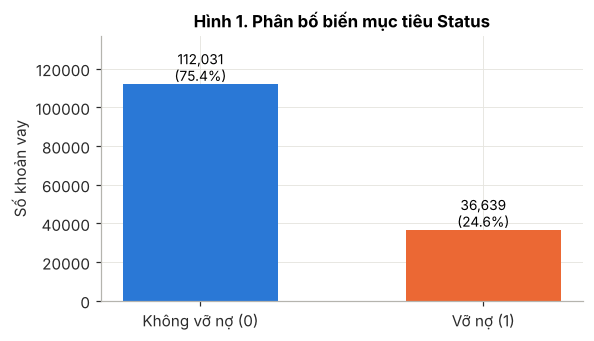

{0: 112031, 1: 36639} 24.64


In [4]:
vc = df["Status"].value_counts().sort_index()
R["status_counts"] = {int(k): int(v) for k, v in vc.items()}
R["default_rate"] = round(df["Status"].mean() * 100, 2)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(["Không vỡ nợ (0)", "Vỡ nợ (1)"], vc.values, color=[C0, C1], width=0.55)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / vc.sum():.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Số khoản vay"); ax.set_ylim(0, vc.max() * 1.22)
ax.set_title("Hình 1. Phân bố biến mục tiêu Status")
savefig("fig01_status")
print(R["status_counts"], R["default_rate"])

**Phân tích Hình 1.** Trong 148.670 khoản vay có 112.031 khoản không vỡ nợ (75,36%) và 36.639 khoản vỡ nợ (24,64%), tỷ lệ khoảng 3:1. Dữ liệu mất cân bằng ở mức vừa phải: một mô hình luôn đoán "không vỡ nợ" đã đạt accuracy 75%, nên Accuracy không phải thước đo phù hợp. Bài học: khi đánh giá mô hình ở Giai đoạn 3 cần dùng AUC, Recall và Precision của lớp vỡ nợ, đồng thời chia train/test có phân tầng (stratify) và đặt class_weight="balanced".

### 1.3 Giá trị khuyết thiếu

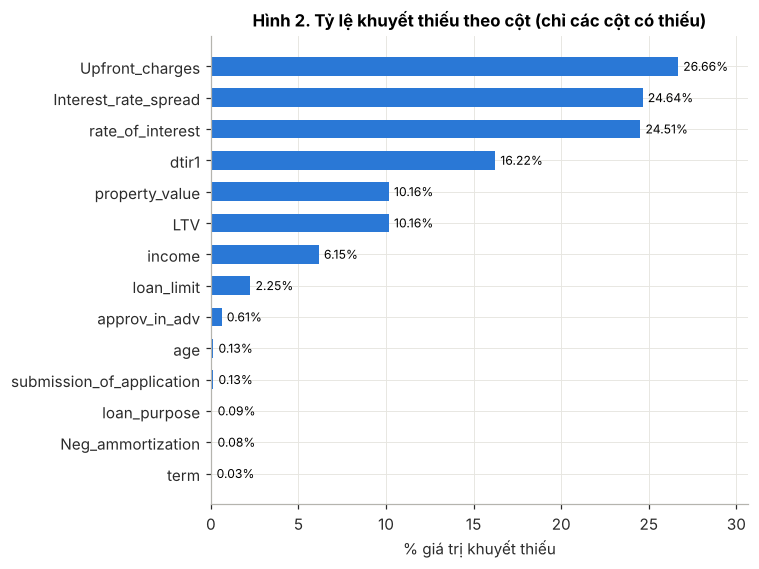

Upfront_charges              26.66
Interest_rate_spread         24.64
rate_of_interest             24.51
dtir1                        16.22
property_value               10.16
LTV                          10.16
income                        6.15
loan_limit                    2.25
approv_in_adv                 0.61
age                           0.13
submission_of_application     0.13
loan_purpose                  0.09
Neg_ammortization             0.08
term                          0.03
Dòng có ít nhất 1 ô thiếu: 33.96 %


In [5]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
R["missing_pct"] = {k: round(float(v), 2) for k, v in miss.items()}
R["rows_with_any_missing_pct"] = round(df.isna().any(axis=1).mean() * 100, 2)
fig, ax = plt.subplots(figsize=(7, 0.32 * len(miss) + 0.8))
ax.barh(miss.index[::-1], miss.values[::-1], color=C0, height=0.6)
for i, v in enumerate(miss.values[::-1]):
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center", fontsize=8)
ax.set_xlabel("% giá trị khuyết thiếu"); ax.set_xlim(0, miss.max() * 1.15)
ax.set_title("Hình 2. Tỷ lệ khuyết thiếu theo cột (chỉ các cột có thiếu)")
savefig("fig02_missing")
print(miss.round(2).to_string()); print("Dòng có ít nhất 1 ô thiếu:", R["rows_with_any_missing_pct"], "%")

**Phân tích Hình 2.** 14/34 cột có giá trị thiếu và 33,96% số dòng thiếu ít nhất một ô, nên không thể xóa dòng thiếu (sẽ mất 1/3 dữ liệu). Có ba nhóm rõ rệt: (i) nhóm thiếu nặng 24–27% gồm Upfront_charges (26,66%), Interest_rate_spread (24,64%), rate_of_interest (24,51%); (ii) nhóm thiếu trung bình gồm dtir1 (16,22%), property_value và LTV (cùng 10,16%, vì LTV được tính từ property_value), income (6,15%); (iii) nhóm thiếu rất ít (<2,3%) như loan_limit, approv_in_adv, age. Điểm đáng chú ý: tỷ lệ thiếu của Interest_rate_spread (24,64%) trùng khớp với tỷ lệ vỡ nợ (24,64%). Đây là dấu hiệu đầu tiên cho thấy việc thiếu dữ liệu không ngẫu nhiên.

Kiểm tra cơ chế thiếu: thiếu ngẫu nhiên (MCAR) hay liên quan tới mục tiêu (MNAR/MAR)? So sánh tỷ lệ vỡ nợ giữa dòng bị thiếu và không thiếu.

In [6]:
rows = []
for c in miss.index:
    m = df[c].isna()
    rows.append({"cột": c, "%thiếu": round(m.mean() * 100, 2),
                 "tỷ lệ vỡ nợ khi THIẾU (%)": round(df.loc[m, "Status"].mean() * 100, 2),
                 "tỷ lệ vỡ nợ khi CÓ (%)": round(df.loc[~m, "Status"].mean() * 100, 2)})
miss_status = pd.DataFrame(rows)
R["miss_vs_status"] = miss_status.to_dict(orient="records")
top3 = ["rate_of_interest", "Interest_rate_spread", "Upfront_charges"]
R["share_default_among_missing_rate"] = round(df.loc[df["rate_of_interest"].isna(), "Status"].mean() * 100, 2)
R["share_missing_rate_among_default"] = round(df.loc[df["Status"] == 1, "rate_of_interest"].isna().mean() * 100, 2)
R["share_missing_rate_among_nondefault"] = round(df.loc[df["Status"] == 0, "rate_of_interest"].isna().mean() * 100, 2)
miss_status

,cột,%thiếu,tỷ lệ vỡ nợ khi THIẾU (%),tỷ lệ vỡ nợ khi CÓ (%)
0,Upfront_charges,26.66,92.04,0.14
1,Interest_rate_spread,24.64,100.00,0.00
2,rate_of_interest,24.51,100.00,0.18
3,dtir1,16.22,67.62,16.32
4,property_value,10.16,99.99,16.13
5,LTV,10.16,99.99,16.13
6,income,6.15,13.54,25.37
7,loan_limit,2.25,26.35,24.61
8,approv_in_adv,0.61,26.54,24.63
9,age,0.13,100.00,24.54


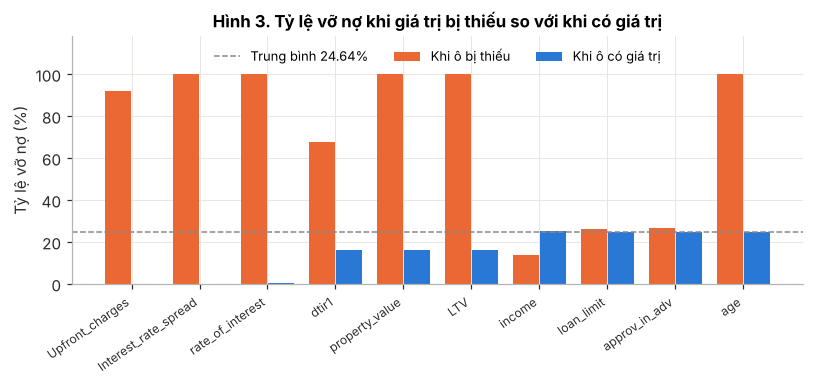

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ms = miss_status.set_index("cột")[["tỷ lệ vỡ nợ khi THIẾU (%)", "tỷ lệ vỡ nợ khi CÓ (%)"]].head(10)
x = np.arange(len(ms)); w = 0.38
ax.bar(x - w / 2 - 0.01, ms.iloc[:, 0], w, color=C1, label="Khi ô bị thiếu")
ax.bar(x + w / 2 + 0.01, ms.iloc[:, 1], w, color=C0, label="Khi ô có giá trị")
ax.axhline(R["default_rate"], color=GRAY, ls="--", lw=1, label=f"Trung bình {R['default_rate']}%")
ax.set_xticks(x); ax.set_xticklabels(ms.index, rotation=35, ha="right", fontsize=8); ax.set_ylim(0, 118)
ax.set_ylabel("Tỷ lệ vỡ nợ (%)"); ax.legend(loc="upper center", ncol=3, fontsize=8.5)
ax.set_title("Hình 3. Tỷ lệ vỡ nợ khi giá trị bị thiếu so với khi có giá trị")
savefig("fig03_missing_vs_status")

**Phân tích Hình 3.** Đây là phát hiện quan trọng nhất của khâu đánh giá dữ liệu. Khi rate_of_interest hoặc Interest_rate_spread bị thiếu, tỷ lệ vỡ nợ là 100%; khi có giá trị thì gần như bằng 0 (0,18% và 0%). Tương tự, property_value/LTV bị thiếu cho 99,99% vỡ nợ, age thiếu cho 100%, dtir1 thiếu cho 67,62% (so với 16,32% khi có). Ngược lại, income thiếu lại có tỷ lệ vỡ nợ thấp hơn (13,54% so với 25,37%). Kết luận: dữ liệu thiếu thuộc loại MNAR (thiếu phụ thuộc vào chính kết quả), nhiều khả năng do quy trình ghi nhận: hồ sơ vỡ nợ không được cập nhật lãi suất, phí, giá trị tài sản. Hệ quả là các cột này mang thông tin "rò rỉ" từ biến mục tiêu và không được điền thiếu một cách máy móc.

### 1.4 Tính nhất quán của dữ liệu
Bộ dữ liệu chỉ có một file nên không cần gộp bảng; ta kiểm tra khóa chính `ID` và các cột hằng.

In [8]:
R["id_unique"] = bool(df["ID"].is_unique)
R["id_min"], R["id_max"] = int(df["ID"].min()), int(df["ID"].max())
R["id_contiguous"] = bool(df["ID"].max() - df["ID"].min() + 1 == len(df))
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
R["const_cols"] = const_cols
print("ID duy nhất:", R["id_unique"], "| liên tục:", R["id_contiguous"], R["id_min"], "→", R["id_max"])
print("Cột hằng:", const_cols, df["year"].unique())

ID duy nhất: True | liên tục: True 24890 → 173559
Cột hằng: ['year'] [2019]


## Giai đoạn 2. Tiền xử lý và làm sạch dữ liệu
### 2.1 Dữ liệu trùng lặp

In [9]:
R["dup_full"] = int(df.duplicated().sum())
R["dup_no_id"] = int(df.drop(columns=["ID"]).duplicated().sum())
print("Trùng toàn dòng:", R["dup_full"], "| Trùng khi bỏ ID:", R["dup_no_id"])

Trùng toàn dòng: 0 | Trùng khi bỏ ID: 0


### 2.2 Sai định dạng và giá trị phân loại bất thường

In [10]:
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in cat_cols:
    print(f"{c:28s}", df[c].value_counts(dropna=False).to_dict())

loan_limit                   {'cf': 135348, 'ncf': 9978, nan: 3344}
Gender                       {'Male': 42346, 'Joint': 41399, 'Sex Not Available': 37659, 'Female': 27266}
approv_in_adv                {'nopre': 124621, 'pre': 23141, nan: 908}
loan_type                    {'type1': 113173, 'type2': 20762, 'type3': 14735}
loan_purpose                 {'p3': 55934, 'p4': 54799, 'p1': 34529, 'p2': 3274, nan: 134}
Credit_Worthiness            {'l1': 142344, 'l2': 6326}
open_credit                  {'nopc': 148114, 'opc': 556}
business_or_commercial       {'nob/c': 127908, 'b/c': 20762}
Neg_ammortization            {'not_neg': 133420, 'neg_amm': 15129, nan: 121}
interest_only                {'not_int': 141560, 'int_only': 7110}
lump_sum_payment             {'not_lpsm': 145286, 'lpsm': 3384}
construction_type            {'sb': 148637, 'mh': 33}
occupancy_type               {'pr': 138201, 'ir': 7340, 'sr': 3129}
Secured_by                   {'home': 148637, 'land': 33}
total_units           

In [11]:
issues = {}
issues["Security_Type"] = df["Security_Type"].value_counts().to_dict()
issues["age"] = df["age"].value_counts(dropna=False).to_dict()
issues["total_units"] = df["total_units"].value_counts().to_dict()
issues["term_values"] = int(df["term"].nunique())
issues["term_top"] = df["term"].value_counts().head(5).to_dict()
issues["income_zero"] = int((df["income"] == 0).sum())
issues["credit_score_range"] = [float(df["Credit_Score"].min()), float(df["Credit_Score"].max())]
issues["dtir1_range"] = [float(df["dtir1"].min()), float(df["dtir1"].max())]
issues["ltv_range"] = [float(df["LTV"].min()), float(df["LTV"].max())]
issues["ltv_gt_100"] = int((df["LTV"] > 100).sum())
issues["rate_range"] = [float(df["rate_of_interest"].min()), float(df["rate_of_interest"].max())]
issues["rate_zero"] = int((df["rate_of_interest"] == 0).sum())
issues["upfront_zero"] = int((df["Upfront_charges"] == 0).sum())
# kiểm tra logic: LTV = loan_amount / property_value * 100
ltv_calc = df["loan_amount"] / df["property_value"] * 100
diff = (ltv_calc - df["LTV"]).abs()
issues["ltv_formula_match_pct"] = round(float((diff[df["LTV"].notna()] < 0.5).mean() * 100), 2)
# cặp cột trùng thông tin
issues["co_applicant_vs_credit_type"] = pd.crosstab(df["credit_type"], df["co-applicant_credit_type"]).to_dict()
# Secured_by vs Security_Type
issues["secured_by_x_security_type"] = {str(k): v for k, v in pd.crosstab(df["Secured_by"], df["Security_Type"]).stack().to_dict().items()}
issues["construction_x_secured"] = {str(k): v for k, v in pd.crosstab(df["construction_type"], df["Secured_by"]).stack().to_dict().items()}
issues["loan_type_x_business"] = {str(k): v for k, v in pd.crosstab(df["loan_type"], df["business_or_commercial"]).stack().to_dict().items()}
R["issues"] = issues
for k, v in issues.items(): print(k, ":", v)

Security_Type : {'direct': 148637, 'Indriect': 33}
age : {'45-54': 34720, '35-44': 32818, '55-64': 32534, '65-74': 20744, '25-34': 19142, '>74': 7175, '<25': 1337, nan: 200}
total_units : {'1U': 146480, '2U': 1477, '3U': 393, '4U': 320}
term_values : 26
term_top : {360.0: 121685, 180.0: 12981, 240.0: 5859, 300.0: 2822, 324.0: 2766}
income_zero : 1260
credit_score_range : [500.0, 900.0]
dtir1_range : [5.0, 61.0]
ltv_range : [0.967478198, 7831.25]
ltv_gt_100 : 1799
rate_range : [0.0, 8.0]
rate_zero : 1
upfront_zero : 20770
ltv_formula_match_pct : 100.0
co_applicant_vs_credit_type : {'CIB': {'CIB': 26870, 'CRIF': 24469, 'EQUI': 2, 'EXP': 23051}, 'EXP': {'CIB': 21282, 'CRIF': 19432, 'EQUI': 15296, 'EXP': 18268}}
secured_by_x_security_type : {"('home', 'Indriect')": 0, "('home', 'direct')": 148637, "('land', 'Indriect')": 33, "('land', 'direct')": 0}
construction_x_secured : {"('mh', 'home')": 0, "('mh', 'land')": 33, "('sb', 'home')": 148637, "('sb', 'land')": 0}
loan_type_x_business : {"(

### 2.3 Ngoại lệ (outliers) của biến số

In [12]:
num_cols = ["loan_amount", "rate_of_interest", "Interest_rate_spread", "Upfront_charges", "term",
            "property_value", "income", "Credit_Score", "LTV", "dtir1"]
out = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out.append({"cột": c, "mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(), "max": s.max(),
                "skew": s.skew(), "Q1": q1, "Q3": q3, "ngưỡng dưới": lo, "ngưỡng trên": hi,
                "số outlier (IQR)": int(((s < lo) | (s > hi)).sum()),
                "% outlier": round(((s < lo) | (s > hi)).mean() * 100, 2),
                "p99": s.quantile(.99)})
outliers = pd.DataFrame(out).set_index("cột")
R["outliers"] = outliers.round(3).reset_index().to_dict(orient="records")
outliers.round(2)

,mean,median,std,min,max,skew,Q1,Q3,ngưỡng dưới,ngưỡng trên,số outlier (IQR),% outlier,p99
cột,,,,,,,,,,,,,
loan_amount,331117.74,296500.00,183909.31,16500.00,3576500.00,1.67,196500.00,436500.00,-163500.00,796500.00,1895,1.27,856500.00
rate_of_interest,4.05,3.99,0.56,0.00,8.00,0.39,3.62,4.38,2.50,5.50,856,0.76,5.50
Interest_rate_spread,0.44,0.39,0.51,-3.64,3.36,0.28,0.08,0.78,-0.97,1.82,445,0.40,1.62
Upfront_charges,3225.00,2596.45,3251.12,0.00,60000.00,1.75,581.49,4812.50,-5765.02,11159.02,2880,2.64,14297.05
term,335.14,360.00,58.41,96.00,360.00,-2.17,360.00,360.00,360.00,360.00,26944,18.13,360.00
property_value,497893.47,418000.00,359935.32,8000.00,16508000.00,4.59,268000.00,628000.00,-272000.00,1168000.00,5266,3.94,1808000.00
income,6957.34,5760.00,6496.59,0.00,578580.00,17.31,3720.00,8520.00,-3480.00,15720.00,6546,4.69,26640.00
Credit_Score,699.79,699.00,115.88,500.00,900.00,0.00,599.00,800.00,297.50,1101.50,0,0.00,897.00
LTV,72.75,75.14,39.97,0.97,7831.25,120.62,60.47,86.18,21.91,124.75,1882,1.41,102.76


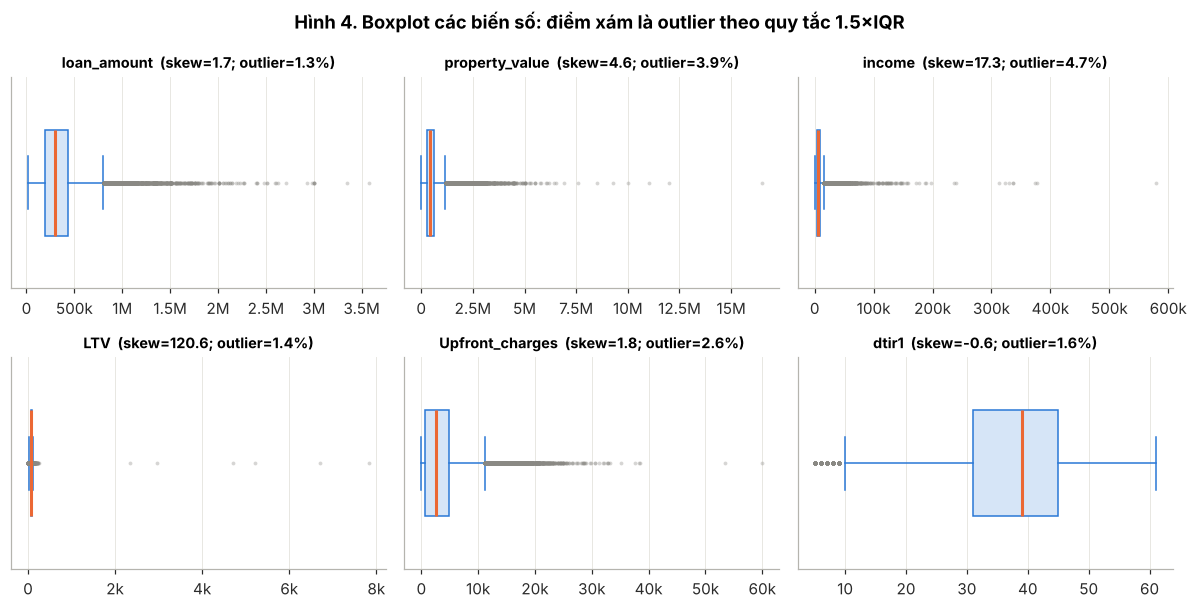

In [13]:
show = ["loan_amount", "property_value", "income", "LTV", "Upfront_charges", "dtir1"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, c in zip(axes.ravel(), show):
    s = df[c].dropna()
    ax.boxplot(s, vert=False, widths=0.5, patch_artist=True, showfliers=True,
               boxprops=dict(facecolor="#d6e5f7", edgecolor=C0), medianprops=dict(color=C1, lw=2),
               whiskerprops=dict(color=C0), capprops=dict(color=C0),
               flierprops=dict(marker="o", markersize=2.5, markerfacecolor=GRAY, markeredgecolor="none", alpha=0.35))
    o = outliers.loc[c]
    ax.set_title(f"{c}  (skew={o['skew']:.1f}; outlier={o['% outlier']:.1f}%)", fontsize=9.5)
    ax.set_yticks([])
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1e6:g}M" if abs(v) >= 1e6 else (f"{v / 1e3:g}k" if abs(v) >= 1e3 else f"{v:g}")))
fig.suptitle("Hình 4. Boxplot các biến số: điểm xám là outlier theo quy tắc 1.5×IQR", fontweight="bold")
savefig("fig04_boxplots")

**Phân tích Hình 4.** Các biến tiền tệ đều lệch phải mạnh: property_value (skew 4,6; 3,9% outlier, max 16,5 triệu so với p99 là 1,81 triệu), income (skew 17,3; 4,7% outlier, max 578.580 so với p99 26.640), loan_amount (skew 1,7; 1,3% outlier). LTV có skew 120,6 do vài giá trị phi lý (max 7.831%, trong khi p99 là 102,8%), đây là lỗi dữ liệu chứ không phải khách hàng thật. Ngược lại dtir1 gần đối xứng (skew −0,6). Riêng term có 18,13% "outlier" theo IQR chỉ vì Q1 = Q3 = 360 tháng (IQR = 0), đây là kỳ hạn hợp lệ (180, 240 tháng) nên không coi là ngoại lệ. Bài học: quy tắc IQR cần đi kèm hiểu biết nghiệp vụ; cách xử lý được chọn là winsorize (giới hạn tại p1–p99) thay vì xóa dòng.

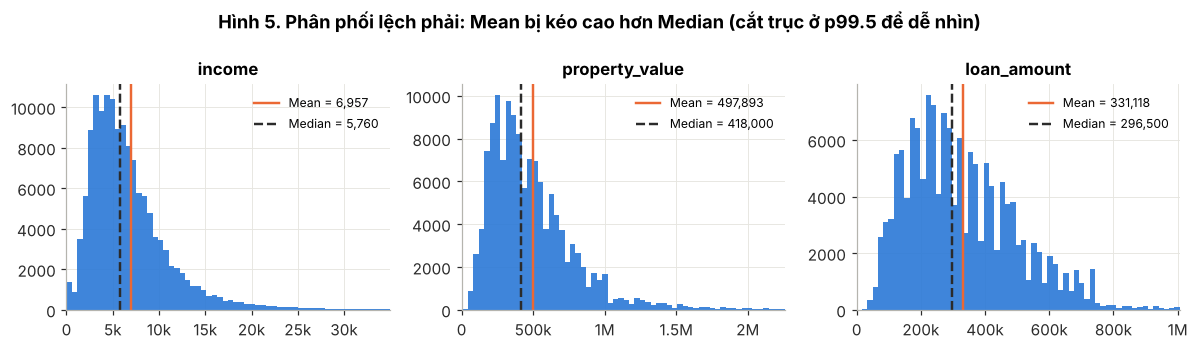

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, c in zip(axes, ["income", "property_value", "loan_amount"]):
    s = df[c].dropna()
    ax.hist(s[s <= s.quantile(.995)], bins=60, color=C0, alpha=0.9)
    ax.axvline(s.mean(), color=C1, lw=1.6, label=f"Mean = {s.mean():,.0f}")
    ax.axvline(s.median(), color=INK, lw=1.6, ls="--", label=f"Median = {s.median():,.0f}")
    ax.set_title(c); ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1e6:g}M" if abs(v) >= 1e6 else (f"{v / 1e3:g}k" if abs(v) >= 1e3 else f"{v:g}")))
    ax.set_xlim(0, s.quantile(.995))
fig.suptitle("Hình 5. Phân phối lệch phải: Mean bị kéo cao hơn Median (cắt trục ở p99.5 để dễ nhìn)", fontweight="bold")
savefig("fig05_skew_hist")

**Phân tích Hình 5.** Với income, Mean = 6.957 nhưng Median = 5.760 (Mean cao hơn 21%); property_value: Mean = 497.893 so với Median = 418.000 (cao hơn 19%); loan_amount: 331.118 so với 296.500 (cao hơn 12%). Đuôi phải dài kéo Mean lên, trong khi Median phản ánh đúng "khách hàng điển hình". Đây là minh chứng định lượng cho lựa chọn điền thiếu bằng Median thay vì Mean ở Giai đoạn 2.

### 2.4 Phát hiện quan trọng: "dấu vân tay" của hồ sơ vỡ nợ (data leakage)
Ở Giai đoạn 1, việc thiếu dữ liệu không ngẫu nhiên. Ta gom các dấu hiệu ghi nhận bất thường thành một cờ
`incomplete_record` và đo xem nó trùng với Status đến mức nào.

In [15]:
flags = {
    "rate_of_interest bị thiếu": df["rate_of_interest"].isna(),
    "property_value bị thiếu": df["property_value"].isna(),
    "credit_type = EQUI": df["credit_type"].eq("EQUI"),
    "income = 0": df["income"].eq(0),
    "age bị thiếu": df["age"].isna(),
    "dtir1 bị thiếu": df["dtir1"].isna(),
}
fl = pd.DataFrame([{"dấu hiệu": k, "số dòng": int(m.sum()), "tỷ lệ vỡ nợ (%)": round(df.loc[m, "Status"].mean() * 100, 2),
                    "% hồ sơ vỡ nợ có dấu hiệu": round((m & df.Status.eq(1)).sum() / df.Status.eq(1).sum() * 100, 2)}
                   for k, m in flags.items()])
R["flags"] = fl.to_dict(orient="records")
artifact = df["property_value"].isna() | df["credit_type"].eq("EQUI") | df["age"].isna() | df["income"].eq(0)
R["artifact_n"] = int(artifact.sum())
R["artifact_default_rate"] = round(df.loc[artifact, "Status"].mean() * 100, 2)
R["artifact_share_of_defaults"] = round((artifact & df.Status.eq(1)).sum() / df.Status.eq(1).sum() * 100, 2)
R["clean_n"] = int((~artifact).sum())
R["clean_default_rate"] = round(df.loc[~artifact, "Status"].mean() * 100, 2)
R["clean_rate_missing_among_default"] = round(df.loc[~artifact & df.Status.eq(1), "rate_of_interest"].isna().mean() * 100, 2)
print(fl.to_string(index=False))
print("Nhóm hồ sơ không đầy đủ:", R["artifact_n"], "dòng, tỷ lệ vỡ nợ", R["artifact_default_rate"], "% , chiếm", R["artifact_share_of_defaults"], "% số ca vỡ nợ")
print("Nhóm hồ sơ đầy đủ (dùng để phân tích):", R["clean_n"], "dòng, tỷ lệ vỡ nợ", R["clean_default_rate"], "%")

                 dấu hiệu  số dòng  tỷ lệ vỡ nợ (%)  % hồ sơ vỡ nợ có dấu hiệu
rate_of_interest bị thiếu    36439           100.00                      99.45
  property_value bị thiếu    15098            99.99                      41.20
       credit_type = EQUI    15298            99.99                      41.75
               income = 0     1260            99.37                       3.42
             age bị thiếu      200           100.00                       0.55
           dtir1 bị thiếu    24121            67.62                      44.52
Nhóm hồ sơ không đầy đủ: 15648 dòng, tỷ lệ vỡ nợ 99.93 % , chiếm 42.68 % số ca vỡ nợ
Nhóm hồ sơ đầy đủ (dùng để phân tích): 133022 dòng, tỷ lệ vỡ nợ 15.79 %


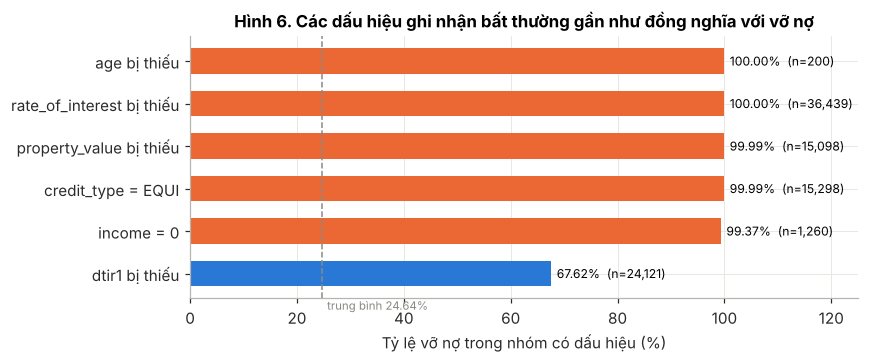

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.4))
f2 = fl.sort_values("tỷ lệ vỡ nợ (%)")
ax.barh(f2["dấu hiệu"], f2["tỷ lệ vỡ nợ (%)"], color=[C1 if v > 90 else C0 for v in f2["tỷ lệ vỡ nợ (%)"]], height=0.6)
for i, (v, n) in enumerate(zip(f2["tỷ lệ vỡ nợ (%)"], f2["số dòng"])):
    ax.text(v + 1, i, f"{v:.2f}%  (n={n:,})", va="center", fontsize=8)
ax.axvline(R["default_rate"], color=GRAY, ls="--", lw=1)
ax.text(R["default_rate"] + 1, -0.85, f"trung bình {R['default_rate']}%", fontsize=7.5, color=GRAY)
ax.set_xlim(0, 125); ax.set_xlabel("Tỷ lệ vỡ nợ trong nhóm có dấu hiệu (%)")
ax.set_title("Hình 6. Các dấu hiệu ghi nhận bất thường gần như đồng nghĩa với vỡ nợ")
savefig("fig06_leak_flags")

**Phân tích Hình 6.** Năm dấu hiệu cho tỷ lệ vỡ nợ từ 99,37% đến 100%: rate_of_interest thiếu (36.439 dòng, bao trùm 99,45% số ca vỡ nợ), credit_type = EQUI (15.298 dòng), property_value thiếu (15.098 dòng), income = 0 (1.260 dòng) và age thiếu (200 dòng). Chỉ riêng cờ "rate_of_interest bị thiếu" đã cho AUC = 0,997 khi dự báo Status. Không có quy luật kinh tế nào giải thích được việc mọi hồ sơ do EQUI chấm điểm đều vỡ nợ, nên đây là dấu vết của quy trình thu thập chứ không phải hành vi khách hàng. Nhóm gộp "hồ sơ không đầy đủ" (property_value thiếu, EQUI, age thiếu hoặc income = 0) có 15.648 dòng, tỷ lệ vỡ nợ 99,93% và chiếm 42,68% tổng số ca vỡ nợ. Nhóm hồ sơ đầy đủ còn 133.022 dòng với tỷ lệ vỡ nợ 15,79%, và đây là nhóm được dùng để phân tích quan hệ ở Giai đoạn 3.

**Minh chứng vì sao không thể điền thiếu "ngây thơ" trên toàn bộ dữ liệu**: nếu điền median cho `LTV` rồi chia nhóm,
nhóm chứa giá trị median sẽ có tỷ lệ vỡ nợ tăng vọt do 15 nghìn hồ sơ vỡ nợ bị "dồn" vào một giá trị.

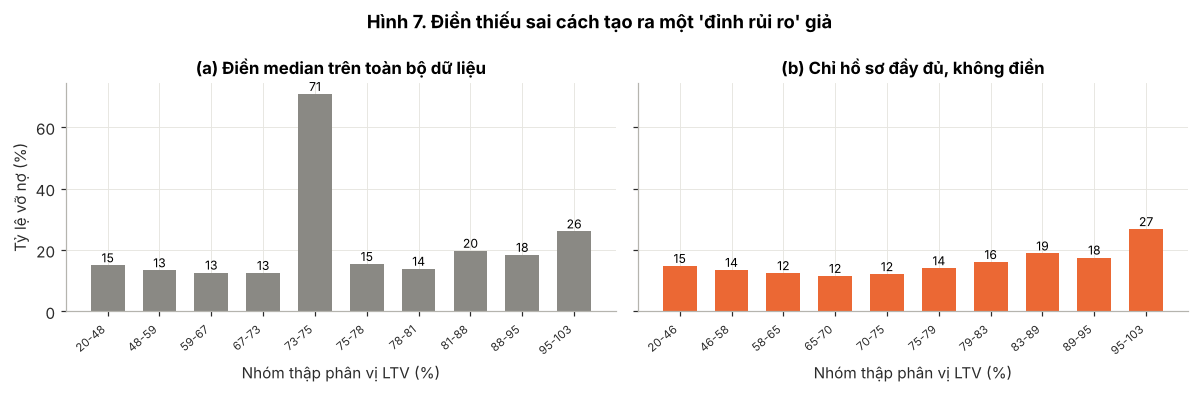

In [17]:
naive = df["LTV"].fillna(df["LTV"].median()).clip(*df["LTV"].quantile([.01, .99]))
g_naive = df.groupby(pd.qcut(naive, 10, duplicates="drop"), observed=True)["Status"].mean() * 100
cl = df.loc[~artifact]
ltv_c = cl["LTV"].clip(*cl["LTV"].quantile([.01, .99]))
g_clean = cl.groupby(pd.qcut(ltv_c, 10, duplicates="drop"), observed=True)["Status"].mean() * 100
R["ltv_naive_bins"] = [{"bin": f"{i.left:.1f}-{i.right:.1f}", "rate": round(float(v), 2)} for i, v in g_naive.items()]
R["ltv_clean_bins"] = [{"bin": f"{i.left:.1f}-{i.right:.1f}", "rate": round(float(v), 2)} for i, v in g_clean.items()]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, g, ttl, col in [(axes[0], g_naive, "(a) Điền median trên toàn bộ dữ liệu", GRAY), (axes[1], g_clean, "(b) Chỉ hồ sơ đầy đủ, không điền", C1)]:
    ax.bar(range(len(g)), g.values, color=col, width=0.65)
    for i, v in enumerate(g.values): ax.text(i, v + 1, f"{v:.0f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{i.left:.0f}-{i.right:.0f}" for i in g.index], rotation=40, ha="right", fontsize=7.5)
    ax.set_title(ttl); ax.set_xlabel("Nhóm thập phân vị LTV (%)")
axes[0].set_ylabel("Tỷ lệ vỡ nợ (%)")
fig.suptitle("Hình 7. Điền thiếu sai cách tạo ra một 'đỉnh rủi ro' giả", fontweight="bold")
savefig("fig07_naive_vs_clean")

**Phân tích Hình 7.** Nếu điền Median (75,1%) cho LTV trên toàn bộ dữ liệu rồi chia nhóm, nhóm LTV 73–75% có tỷ lệ vỡ nợ 70,85% (22.514 hồ sơ), trong khi các nhóm lân cận chỉ 12,5–15,5%. Đỉnh này hoàn toàn giả tạo: 15 nghìn hồ sơ vỡ nợ bị thiếu property_value đã bị dồn vào đúng giá trị Median. Khi chỉ dùng hồ sơ đầy đủ (hình b), quan hệ thật hiện ra: tỷ lệ vỡ nợ giảm nhẹ từ 14,82% xuống 11,57% ở LTV 65–70%, rồi tăng đều lên 26,81% ở nhóm LTV 95–103%. Đây là minh chứng rằng lựa chọn kỹ thuật điền thiếu có thể đảo ngược kết luận phân tích.

### 2.5 Làm sạch: các bước và lý do
1. Bỏ `ID` (khóa định danh) và `year` (hằng số 2019, không mang thông tin).
2. Sửa lỗi chính tả `Security_Type`: `Indriect` → `Indirect`; chuẩn hóa chữ hoa `Region` (`south` → `South`). Loại cột trùng thông tin khỏi mô hình:
   `business_or_commercial` ≡ (`loan_type` = type2); `Secured_by`, `construction_type`, `Security_Type` cùng tách ra đúng 33 dòng giống nhau (land = mh = Indirect).
3. Loại khỏi mô hình 3 cột `rate_of_interest`, `Interest_rate_spread`, `Upfront_charges`: thiếu ở ~100% hồ sơ vỡ nợ và 0% hồ sơ tốt → rò rỉ mục tiêu.
4. Tách nhóm hồ sơ không đầy đủ (`incomplete_record`) ra phân tích riêng; phân tích quan hệ và mô hình dùng nhóm hồ sơ đầy đủ.
5. `age` dạng khoảng chữ → mã hóa thứ tự (ordinal) vì có thứ bậc tự nhiên.
6. Ngoại lệ: không xóa dòng; winsorize tại phân vị 1%-99% cho `loan_amount`, `property_value`, `income`, `LTV`.
7. Thiếu còn lại (`dtir1`, `income`, ...): điền **median** cho biến số (phân phối lệch), **mode** cho biến phân loại,
   kèm cột cờ thiếu; việc điền được fit **chỉ trên tập train** trong Pipeline để tránh rò rỉ sang tập test.
8. Mã hóa: One-Hot cho biến danh nghĩa (2-4 mức, không có thứ bậc), Ordinal cho `age`.
9. Chuẩn hóa: **RobustScaler** (trừ median, chia IQR) vì các biến tiền tệ lệch phải và còn đuôi dài.

In [18]:
dfc = df.drop(columns=["ID", "year"]).copy()
dfc["Security_Type"] = dfc["Security_Type"].replace({"Indriect": "Indirect"})
dfc["Region"] = dfc["Region"].str.title()  # 'south', 'central' viết thường không nhất quán với 'North'
age_order = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]
dfc["age_ord"] = dfc["age"].map({a: i for i, a in enumerate(age_order)})
dfc["incomplete_record"] = artifact.astype(int).values
LEAK = ["rate_of_interest", "Interest_rate_spread", "Upfront_charges"]

wins = ["loan_amount", "property_value", "income", "LTV"]
R["winsor_bounds"] = {}
clean = dfc[dfc["incomplete_record"] == 0].copy()
for c in wins:
    lo, hi = clean[c].quantile([.01, .99])
    R["winsor_bounds"][c] = [float(lo), float(hi)]
    clean[c + "_w"] = clean[c].clip(lo, hi)
R["clean_missing"] = {c: round(float(v), 2) for c, v in (clean.drop(columns=LEAK).isna().mean() * 100).items() if v > 0}
fill_cmp = pd.DataFrame({c: {"mean": clean[c].mean(), "median": clean[c].median(), "skew": clean[c].skew(), "% thiếu": clean[c].isna().mean() * 100}
                         for c in ["income", "dtir1", "loan_amount", "property_value", "LTV"]}).T
R["fill_cmp"] = fill_cmp.round(3).reset_index().to_dict(orient="records")
print("Thiếu còn lại trong nhóm đầy đủ (%):", R["clean_missing"])
print("Ngưỡng winsorize:", R["winsor_bounds"])
fill_cmp.round(2)

Thiếu còn lại trong nhóm đầy đủ (%): {'loan_limit': 2.23, 'approv_in_adv': 0.61, 'loan_purpose': 0.08, 'term': 0.02, 'Neg_ammortization': 0.08, 'income': 6.72, 'dtir1': 6.63, 'income_w': 6.72}
Ngưỡng winsorize: {'loan_amount': [66500.0, 836500.0], 'property_value': [88000.0, 1808000.0], 'income': [1260.0, 26520.0], 'LTV': [19.61009174, 102.7597403]}


,mean,median,skew,% thiếu
income,7032.87,5820.00,18.50,6.72
dtir1,37.80,39.00,-0.54,6.63
loan_amount,331491.96,296500.00,1.56,0.00
property_value,498247.93,418000.00,4.59,0.00
LTV,72.74,75.12,120.54,0.00


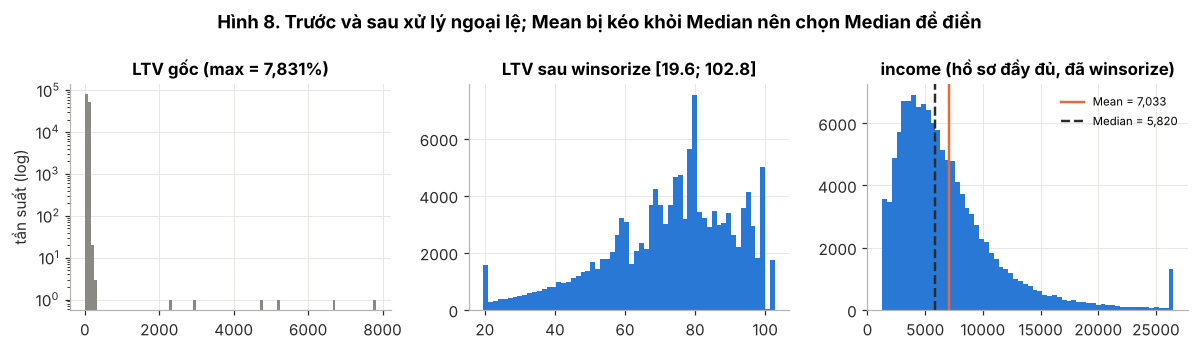

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].hist(df["LTV"].dropna(), bins=100, color=GRAY)
axes[0].set_yscale("log"); axes[0].set_title(f"LTV gốc (max = {df['LTV'].max():,.0f}%)"); axes[0].set_ylabel("tần suất (log)")
axes[1].hist(clean["LTV_w"], bins=60, color=C0)
axes[1].set_title(f"LTV sau winsorize [{R['winsor_bounds']['LTV'][0]:.1f}; {R['winsor_bounds']['LTV'][1]:.1f}]")
inc = clean["income_w"].dropna()
axes[2].hist(inc, bins=60, color=C0)
axes[2].axvline(clean["income"].mean(), color=C1, lw=1.6, label=f"Mean = {clean['income'].mean():,.0f}")
axes[2].axvline(clean["income"].median(), color=INK, lw=1.6, ls="--", label=f"Median = {clean['income'].median():,.0f}")
axes[2].legend(fontsize=7.5); axes[2].set_title("income (hồ sơ đầy đủ, đã winsorize)")
fig.suptitle("Hình 8. Trước và sau xử lý ngoại lệ; Mean bị kéo khỏi Median nên chọn Median để điền", fontweight="bold")
savefig("fig08_winsor")

**Phân tích Hình 8.** LTV gốc trải tới 7.831% (trục log cho thấy vài điểm cô lập ở 2.000–8.000%); sau khi winsorize tại p1–p99, LTV nằm trong [19,6%; 102,8%], đúng miền nghiệp vụ của khoản vay thế chấp, và phân phối có các đỉnh ở 80% và 100% (các ngưỡng LTV phổ biến khi cho vay). Với income trong nhóm hồ sơ đầy đủ, Mean = 7.033 vẫn lệch khỏi Median = 5.820 (skew 18,5), nên Median được dùng để điền 6,72% income còn thiếu. Winsorize giữ nguyên 100% số dòng (không làm mất thông tin về khách hàng thu nhập cao), chỉ giới hạn ảnh hưởng của giá trị cực đoan.

## Giai đoạn 3. Phân tích và trực quan hóa
Phân tích trên **nhóm hồ sơ đầy đủ** để tránh kết luận bị chi phối bởi lỗi ghi nhận.

Giả thuyết ban đầu (theo kinh nghiệm tín dụng):
- **H1**: Điểm tín dụng (`Credit_Score`) càng thấp, tỷ lệ vỡ nợ càng cao.
- **H2**: Tỷ lệ khoản vay trên giá trị tài sản (`LTV`) càng cao, tỷ lệ vỡ nợ càng cao.
- **H3**: Tỷ lệ nợ trên thu nhập (`dtir1`) càng cao, tỷ lệ vỡ nợ càng cao.
- **H4**: Thu nhập càng cao, tỷ lệ vỡ nợ càng thấp.
- **H5**: Nhóm tuổi có liên hệ với khả năng vỡ nợ (người trẻ rủi ro hơn).
- **H6**: Đặc điểm sản phẩm (loại vay, mục đích, trả gộp cuối kỳ, khấu hao âm...) và vùng/giới tính liên hệ với vỡ nợ.

In [20]:
def mwu(col):
    a = clean.loc[clean.Status == 0, col].dropna(); b = clean.loc[clean.Status == 1, col].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 1 - 2 * u / (len(a) * len(b))  # rank-biserial (dương: nhóm vỡ nợ có giá trị cao hơn)
    rho, p_rho = stats.spearmanr(clean[[col, "Status"]].dropna()[col], clean[[col, "Status"]].dropna()["Status"])
    return {"median_0": float(a.median()), "median_1": float(b.median()), "mean_0": float(a.mean()), "mean_1": float(b.mean()),
            "U": float(u), "p": float(p), "rank_biserial": float(r_rb), "spearman": float(rho)}

R["tests"] = {c: mwu(c) for c in ["Credit_Score", "LTV", "dtir1", "income", "loan_amount", "property_value"]}
pd.DataFrame(R["tests"]).T

,median_0,median_1,mean_0,mean_1,U,p,rank_biserial,spearman
Credit_Score,699.000000,700.000000,699.522907,700.662461,1.169685e+09,1.937174e-01,0.005642,0.003563
LTV,74.504405,79.362416,72.064994,76.313952,1.009704e+09,1.727414e-233,0.141643,0.089456
dtir1,38.000000,42.000000,37.371667,40.056384,8.666188e+08,0.000000e+00,0.167885,0.106923
income,6000.000000,4680.000000,7204.604213,6137.902693,1.261537e+09,0.000000e+00,-0.213080,-0.135646
loan_amount,306500.000000,266500.000000,334995.804321,312803.209218,1.320124e+09,1.608071e-174,-0.122247,-0.077221
property_value,428000.000000,348000.000000,505614.443849,458956.575564,1.371369e+09,0.000000e+00,-0.165811,-0.104730


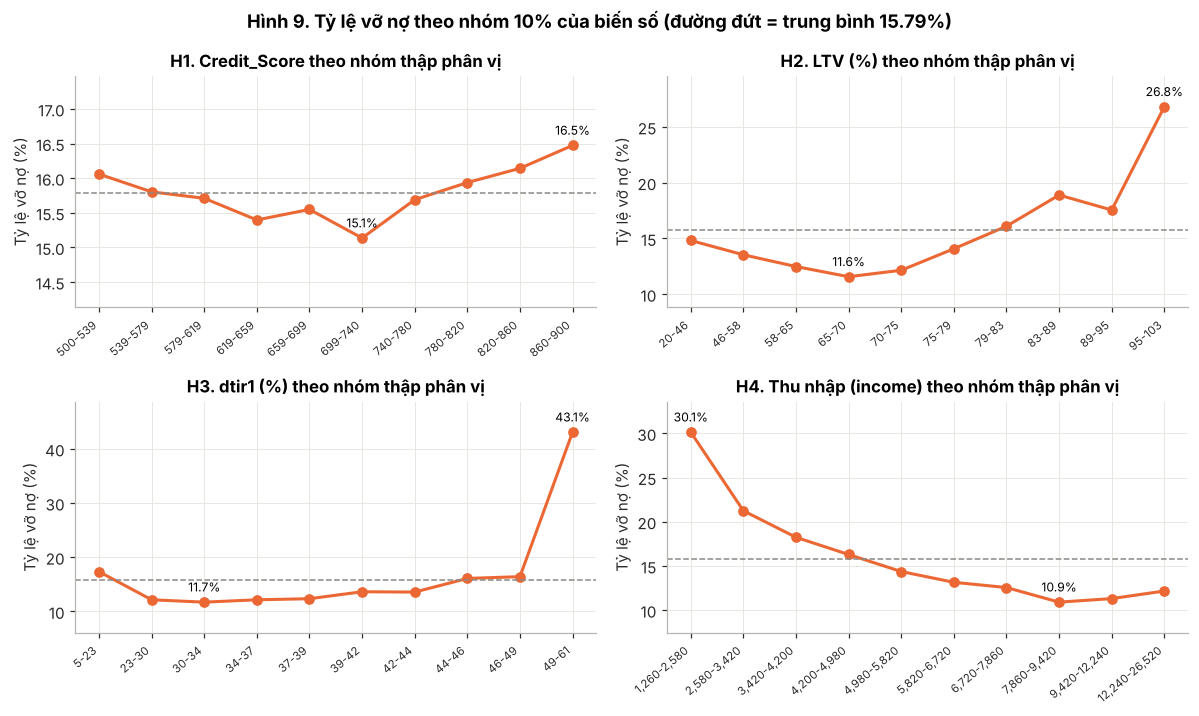

In [21]:
def rate_by_bin(col, q=10):
    s = clean[[col, "Status"]].dropna()
    g = s.groupby(pd.qcut(s[col], q=q, duplicates="drop"), observed=True)["Status"].agg(["mean", "size"])
    g["mean"] *= 100
    return g

fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
R["bins"] = {}
for ax, (c, ttl) in zip(axes.ravel(), [("Credit_Score", "H1. Credit_Score"), ("LTV_w", "H2. LTV (%)"),
                                       ("dtir1", "H3. dtir1 (%)"), ("income_w", "H4. Thu nhập (income)")]):
    g = rate_by_bin(c)
    R["bins"][c] = [{"bin": f"{i.left:,.0f}-{i.right:,.0f}", "rate": round(float(r), 2), "n": int(n)} for i, (r, n) in zip(g.index, g.values)]
    ax.plot(range(len(g)), g["mean"], marker="o", color=C1, lw=2, markersize=6)
    ax.axhline(R["clean_default_rate"], color=GRAY, ls="--", lw=1)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([f"{iv.left:,.0f}-{iv.right:,.0f}" for iv in g.index], rotation=40, ha="right", fontsize=7.5)
    ax.set_ylabel("Tỷ lệ vỡ nợ (%)"); ax.set_title(ttl + " theo nhóm thập phân vị")
    lo_, hi_ = g["mean"].min(), g["mean"].max(); pad = max((hi_ - lo_) * 0.18, 1)
    ax.set_ylim(min(lo_, R["clean_default_rate"]) - pad, max(hi_, R["clean_default_rate"]) + pad)
    for i in sorted({int(np.argmax(g["mean"].values)), int(np.argmin(g["mean"].values))}):
        ax.annotate(f"{g['mean'].iloc[i]:.1f}%", (i, g["mean"].iloc[i]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
fig.suptitle(f"Hình 9. Tỷ lệ vỡ nợ theo nhóm 10% của biến số (đường đứt = trung bình {R['clean_default_rate']}%)", fontweight="bold")
savefig("fig09_rate_by_decile")

**Phân tích Hình 9.** H1 (Credit_Score): tỷ lệ vỡ nợ chỉ dao động 15,1–16,5% giữa 10 nhóm điểm, đường gần như phẳng; kiểm định Mann–Whitney p = 0,19, Spearman ρ = 0,004, nên bác bỏ H1. H2 (LTV): đường hình chữ J, thấp nhất 11,57% ở LTV 65–70% và cao nhất 26,81% ở LTV 95–103% (gấp 2,3 lần); median LTV của nhóm vỡ nợ là 79,4% so với 74,5% (p < 10⁻²⁰⁰). H3 (dtir1): đường phẳng quanh 12–16% cho tới dtir1 ≈ 49%, rồi nhảy vọt lên 43,09% ở nhóm 49–61% (gấp 3,7 lần mức thấp nhất). Quan hệ mang tính ngưỡng chứ không tuyến tính. H4 (income): giảm đơn điệu từ 30,14% ở nhóm thu nhập thấp nhất (1.260–2.580) xuống khoảng 11% từ mức 7.860 trở lên; median thu nhập nhóm vỡ nợ là 4.680 so với 6.000. Bài học: ba biến năng lực tài chính (LTV, dtir1, income) có tác động rõ, còn điểm tín dụng trong bộ dữ liệu này gần như không có giá trị phân biệt.

In [22]:
def chi2_table(col, data):
    ct = pd.crosstab(data[col], data["Status"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); k = min(ct.shape) - 1
    v = np.sqrt(chi2 / (n * k)) if k > 0 else np.nan
    rate = (ct[1] / ct.sum(axis=1) * 100).round(2)
    return {"chi2": float(chi2), "p": float(p), "dof": int(dof), "cramers_v": float(v),
            "rates": {str(k_): float(v_) for k_, v_ in rate.items()}, "n": {str(k_): int(v_) for k_, v_ in ct.sum(axis=1).items()}}

cat_test_cols = ["age", "credit_type", "co-applicant_credit_type", "loan_type", "loan_purpose", "Region", "Gender",
                 "loan_limit", "approv_in_adv", "Credit_Worthiness", "open_credit", "business_or_commercial",
                 "Neg_ammortization", "interest_only", "lump_sum_payment", "occupancy_type",
                 "total_units", "submission_of_application"]
R["chi2"] = {c: chi2_table(c, clean) for c in cat_test_cols}
R["chi2_full_credit_type"] = chi2_table("credit_type", dfc)
chi_df = pd.DataFrame({c: {"chi2": v["chi2"], "p": v["p"], "Cramér's V": v["cramers_v"]} for c, v in R["chi2"].items()}).T
chi_df = chi_df.sort_values("Cramér's V", ascending=False)
chi_df.round(4)

,chi2,p,Cramér's V
lump_sum_payment,4149.6223,0.0000,0.1766
Neg_ammortization,2960.2475,0.0000,0.1492
submission_of_application,2141.7620,0.0000,0.1269
loan_type,1488.3043,0.0000,0.1058
business_or_commercial,1483.7781,0.0000,0.1056
Gender,854.2263,0.0000,0.0801
co-applicant_credit_type,688.5127,0.0000,0.0719
loan_purpose,407.5761,0.0000,0.0554
age,357.7220,0.0000,0.0519
Region,339.7370,0.0000,0.0505


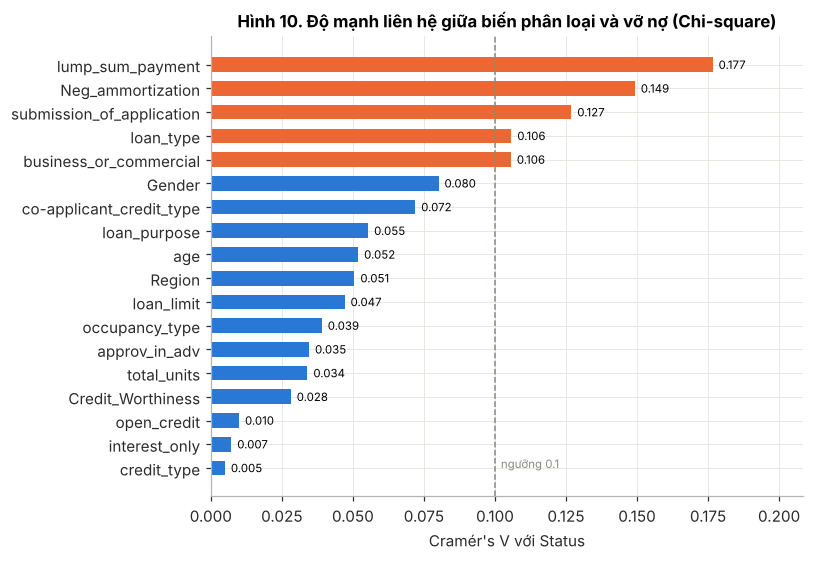

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
cv = chi_df["Cramér's V"].sort_values()
xmax = max(cv.max() * 1.18, 0.13)
ax.barh(cv.index, cv.values, color=[C1 if v >= 0.1 else C0 for v in cv.values], height=0.62)
for i, v in enumerate(cv.values): ax.text(v + xmax * 0.01, i, f"{v:.3f}", va="center", fontsize=7.5)
ax.axvline(0.1, color=GRAY, ls="--", lw=1); ax.text(0.1 + xmax * 0.01, 0, "ngưỡng 0.1", fontsize=7.5, color=GRAY)
ax.set_xlabel("Cramér's V với Status"); ax.set_xlim(0, xmax)
ax.set_title("Hình 10. Độ mạnh liên hệ giữa biến phân loại và vỡ nợ (Chi-square)")
savefig("fig10_cramers_v")

**Phân tích Hình 10.** Tất cả biến đều có p < 0,05 do mẫu rất lớn (133 nghìn dòng), nên cần nhìn độ lớn hiệu ứng (Cramér's V) thay vì chỉ nhìn p-value. Năm biến vượt ngưỡng 0,1: lump_sum_payment (0,177), Neg_ammortization (0,149), submission_of_application (0,127), loan_type và business_or_commercial (cùng 0,106, vì hai cột này trùng thông tin). Các biến nhân khẩu học như Gender (0,080), age (0,052), Region (0,051) chỉ có liên hệ yếu. Đáng chú ý credit_type chỉ còn V = 0,005 (p = 0,19, không có ý nghĩa thống kê) trong nhóm hồ sơ đầy đủ. Kết luận: đặc điểm cấu trúc sản phẩm vay quan trọng hơn đặc điểm nhân khẩu học của người vay.

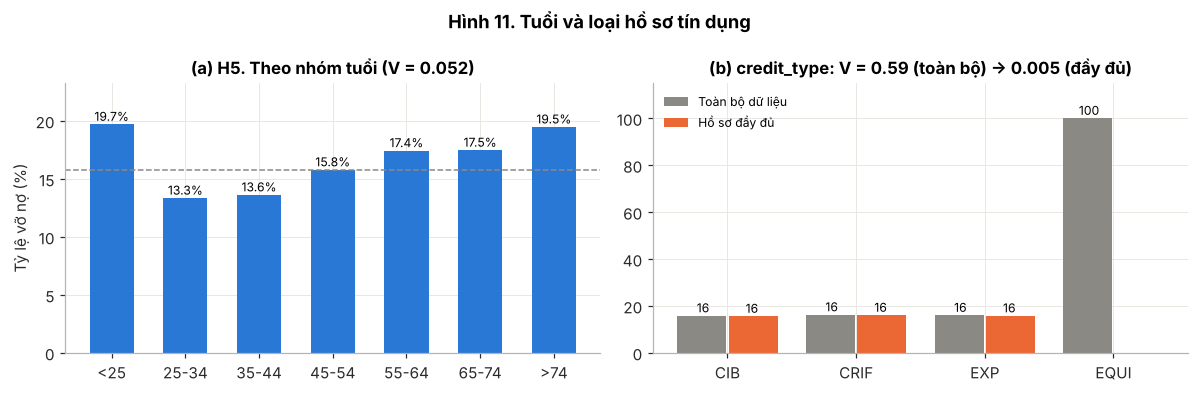

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
a = R["chi2"]["age"]
ages = [x for x in age_order if x in a["rates"]]
axes[0].bar(ages, [a["rates"][x] for x in ages], color=C0, width=0.6)
for i, x in enumerate(ages): axes[0].text(i, a["rates"][x] + 0.3, f"{a['rates'][x]:.1f}%", ha="center", fontsize=8)
axes[0].axhline(R["clean_default_rate"], color=GRAY, ls="--", lw=1)
axes[0].set_title(f"(a) H5. Theo nhóm tuổi (V = {a['cramers_v']:.3f})"); axes[0].set_ylabel("Tỷ lệ vỡ nợ (%)")
axes[0].set_ylim(0, max(a["rates"].values()) * 1.18)
ctf, ctc = R["chi2_full_credit_type"], R["chi2"]["credit_type"]
keys = ["CIB", "CRIF", "EXP", "EQUI"]; x = np.arange(len(keys)); w = 0.38
axes[1].bar(x - w / 2 - 0.01, [ctf["rates"].get(k, 0) for k in keys], w, color=GRAY, label="Toàn bộ dữ liệu")
axes[1].bar(x + w / 2 + 0.01, [ctc["rates"].get(k, 0) for k in keys], w, color=C1, label="Hồ sơ đầy đủ")
for i, k in enumerate(keys):
    axes[1].text(i - w / 2, ctf["rates"].get(k, 0) + 1.5, f"{ctf['rates'].get(k, 0):.0f}", ha="center", fontsize=8)
    if k in ctc["rates"]: axes[1].text(i + w / 2, ctc["rates"][k] + 1.5, f"{ctc['rates'][k]:.0f}", ha="center", fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels(keys); axes[1].set_ylim(0, 115); axes[1].legend(loc="upper left", fontsize=8)
axes[1].set_title(f"(b) credit_type: V = {ctf['cramers_v']:.2f} (toàn bộ) → {ctc['cramers_v']:.3f} (đầy đủ)")
fig.suptitle("Hình 11. Tuổi và loại hồ sơ tín dụng", fontweight="bold")
savefig("fig11_age_credit_type")

**Phân tích Hình 11.** (a) H5 được chấp nhận một phần: tỷ lệ vỡ nợ có dạng chữ U theo tuổi, thấp nhất ở 25–34 (13,34%) và 35–44 (13,62%), cao nhất ở hai đầu là <25 (19,70%) và >74 (19,47%). Giả thuyết "người trẻ rủi ro hơn" chỉ đúng một nửa vì người cao tuổi rủi ro tương đương. Tuy vậy, hiệu ứng yếu (V = 0,052) và nhóm <25 chỉ có 1.183 hồ sơ. (b) Trên toàn bộ dữ liệu, credit_type có V = 0,59 (rất mạnh) vì EQUI có 99,99% vỡ nợ. Sau khi loại hồ sơ không đầy đủ, ba loại còn lại CIB, CRIF, EXP có tỷ lệ gần như bằng nhau (15,59%, 16,02%, 15,77%) và V giảm còn 0,005. Bài học: một liên hệ "rất mạnh" có thể hoàn toàn là sản phẩm của lỗi dữ liệu.

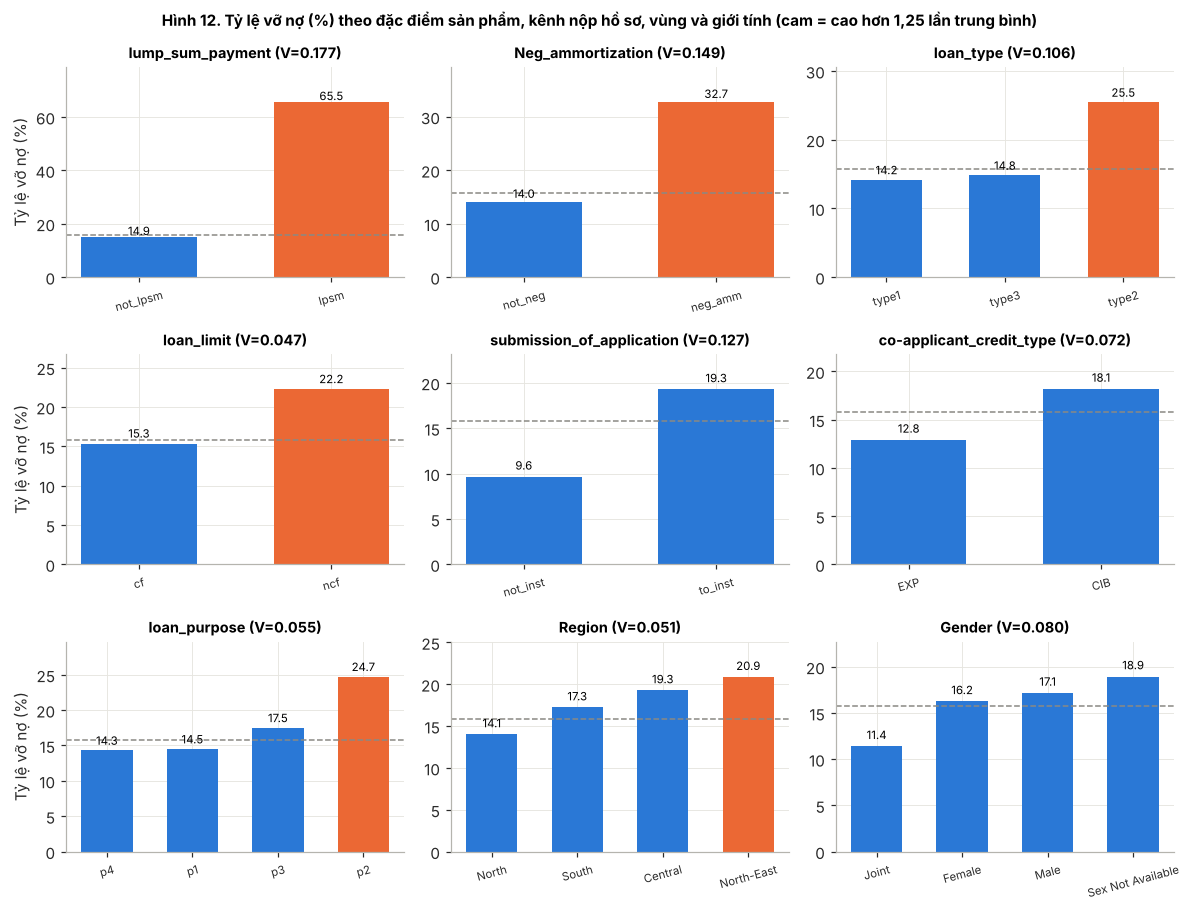

In [25]:
show_cats = ["lump_sum_payment", "Neg_ammortization", "loan_type", "loan_limit",
             "submission_of_application", "co-applicant_credit_type", "loan_purpose", "Region", "Gender"]
fig, axes = plt.subplots(3, 3, figsize=(11, 8.4))
for ax, c in zip(axes.ravel(), show_cats):
    t = R["chi2"][c]; keys = sorted(t["rates"], key=lambda k: t["rates"][k])
    ax.bar(keys, [t["rates"][k] for k in keys], color=[C1 if t["rates"][k] > R["clean_default_rate"] * 1.25 else C0 for k in keys], width=0.6)
    for i, k in enumerate(keys): ax.text(i, t["rates"][k] + 0.8, f"{t['rates'][k]:.1f}", ha="center", fontsize=7.5)
    ax.axhline(R["clean_default_rate"], color=GRAY, ls="--", lw=1)
    ax.set_title(f"{c} (V={t['cramers_v']:.3f})", fontsize=9.5); ax.tick_params(axis="x", labelsize=7.5, rotation=15)
    ax.set_ylim(0, max(t["rates"].values()) * 1.2)
for r in range(3): axes[r, 0].set_ylabel("Tỷ lệ vỡ nợ (%)")
fig.suptitle("Hình 12. Tỷ lệ vỡ nợ (%) theo đặc điểm sản phẩm, kênh nộp hồ sơ, vùng và giới tính (cam = cao hơn 1,25 lần trung bình)", fontweight="bold", fontsize=10)
savefig("fig12_cat_rates")

**Phân tích Hình 12.** Khoản vay trả gộp cuối kỳ (lpsm) vỡ nợ 65,54% so với 14,95% (gấp 4,4 lần, dù chỉ 2.194 hồ sơ); khoản vay khấu hao âm (neg_amm) 32,71% so với 14,03% (gấp 2,3 lần, 12.455 hồ sơ). Loại vay type2 (trùng với vay kinh doanh/thương mại) có 25,46% so với khoảng 14,2–14,8% của type1/type3. Khoản vay vượt hạn mức chuẩn (ncf) có 22,23% so với 15,31% (cf). Hồ sơ nộp qua kênh to_inst vỡ nợ 19,27%, gấp đôi kênh not_inst (9,64%). Người đồng vay chấm điểm bởi CIB có 18,13% so với 12,85% của EXP. Mục đích vay p2 có 24,73% (n = 2.911) so với 14,30% của p4. Theo vùng, North-East (20,90%, chỉ 1.086 hồ sơ) và Central (19,31%) cao hơn North (14,05%). Theo giới tính, hồ sơ vay chung (Joint) thấp nhất (11,38%), còn hồ sơ không khai giới tính cao nhất (18,93%). Bài học: cấu trúc trả nợ "dồn gánh nặng về sau" (balloon, khấu hao âm) là yếu tố rủi ro lớn nhất; có thêm người cùng vay giúp giảm rủi ro.

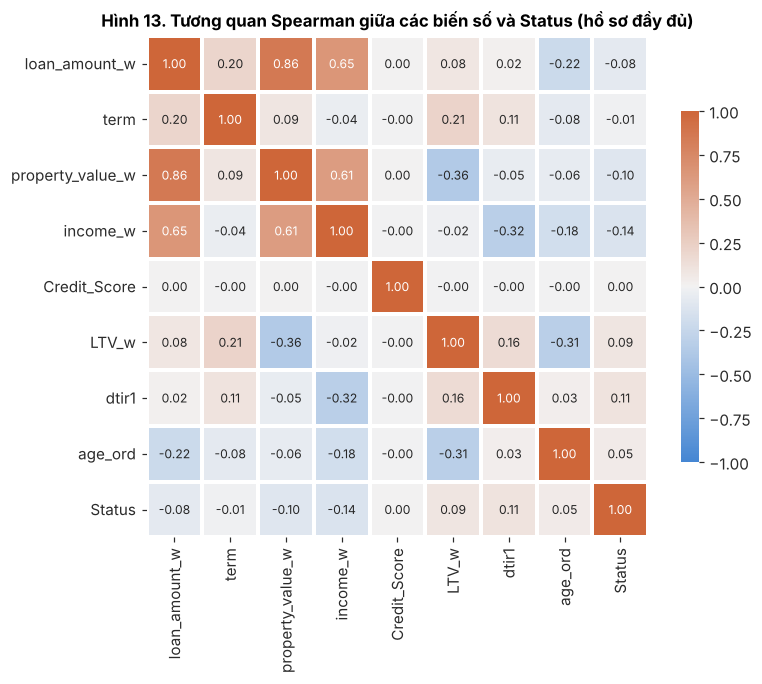

{'loan_amount_w': -0.077, 'term': -0.009, 'property_value_w': -0.105, 'income_w': -0.136, 'Credit_Score': 0.004, 'LTV_w': 0.089, 'dtir1': 0.107, 'age_ord': 0.047}
{'loan_amount_w~property_value_w': 0.857, 'loan_amount_w~income_w': 0.654, 'property_value_w~income_w': 0.609, 'property_value_w~LTV_w': -0.364, 'income_w~dtir1': -0.317, 'LTV_w~age_ord': -0.313}


In [26]:
corr_cols = ["loan_amount_w", "term", "property_value_w", "income_w", "Credit_Score", "LTV_w", "dtir1", "age_ord", "Status"]
corr = clean[corr_cols].corr(method="spearman")
R["corr_status"] = corr["Status"].drop("Status").round(3).to_dict()
R["corr_pairs"] = {f"{a}~{b}": round(float(corr.loc[a, b]), 3) for i, a in enumerate(corr_cols) for b in corr_cols[i + 1:] if abs(corr.loc[a, b]) >= 0.3}
fig, ax = plt.subplots(figsize=(7.5, 6.2))
cmap = sns.diverging_palette(250, 25, s=80, l=55, center="light", as_cmap=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, center=0, square=True,
            linewidths=1.5, linecolor="white", annot_kws={"size": 8}, cbar_kws={"shrink": .7}, ax=ax)
ax.grid(False)
ax.set_title("Hình 13. Tương quan Spearman giữa các biến số và Status (hồ sơ đầy đủ)")
savefig("fig13_corr_heatmap")
print(R["corr_status"]); print(R["corr_pairs"])

**Phân tích Hình 13.** Không biến số nào có tương quan mạnh với Status: lớn nhất là income (ρ = −0,14), dtir1 (+0,11), property_value (−0,10), LTV (+0,09), loan_amount (−0,08). Credit_Score có ρ = 0,00 với mọi biến, bất thường với một điểm tín dụng thật (điểm phân phối đều 500–900, mỗi khoảng 50 điểm có khoảng 18.500 hồ sơ), gợi ý cột này có thể đã bị ẩn danh hoặc sinh ngẫu nhiên. Giữa các biến đầu vào có đa cộng tuyến: loan_amount–property_value ρ = 0,86, loan_amount–income 0,65, property_value–income 0,61. Vì vậy không nên dùng đồng thời cả ba ở dạng thô trong hồi quy tuyến tính; các tỷ số như LTV hay loan/income mang thông tin rủi ro tốt hơn. Hệ số tương quan nhỏ không có nghĩa là không có tác động: Hình 9 cho thấy quan hệ mang tính ngưỡng mà tương quan đơn điệu đánh giá thấp.

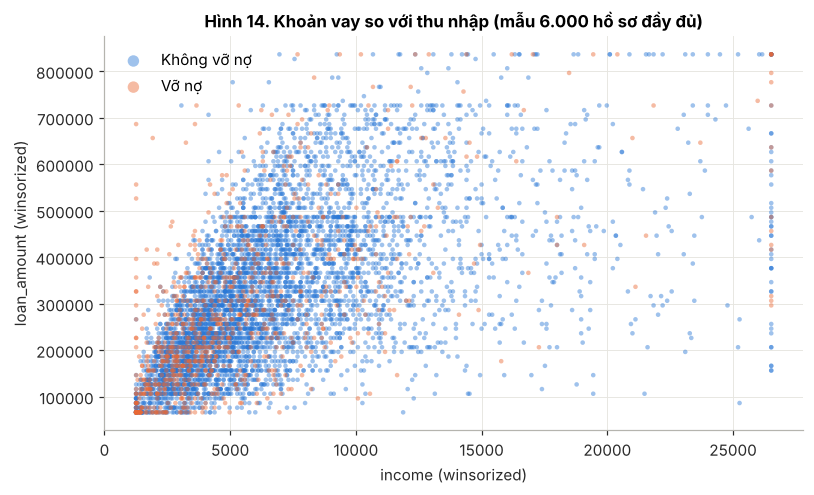

[{'bin': '0.05-2.82', 'rate': 14.57}, {'bin': '2.82-3.85', 'rate': 14.06}, {'bin': '3.85-4.88', 'rate': 14.08}, {'bin': '4.88-6.20', 'rate': 14.41}, {'bin': '6.20-2106.25', 'rate': 23.39}]


In [27]:
samp = clean.dropna(subset=["income_w"]).sample(6000, random_state=42)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for s_, col, lab in [(0, C0, "Không vỡ nợ"), (1, C1, "Vỡ nợ")]:
    d = samp[samp.Status == s_]
    ax.scatter(d["income_w"], d["loan_amount_w"], s=9, color=col, alpha=0.45, label=lab, edgecolors="none")
ax.set_xlabel("income (winsorized)"); ax.set_ylabel("loan_amount (winsorized)")
ax.legend(markerscale=2.5); ax.set_title("Hình 14. Khoản vay so với thu nhập (mẫu 6.000 hồ sơ đầy đủ)")
savefig("fig14_scatter_income_loan")
lti = clean["loan_amount"] / (clean["income"].replace(0, np.nan) * 12)
g_lti = clean.groupby(pd.qcut(lti, 5), observed=True)["Status"].mean() * 100
R["lti_quintiles"] = [{"bin": f"{i.left:.2f}-{i.right:.2f}", "rate": round(float(v), 2)} for i, v in g_lti.items()]
print(R["lti_quintiles"])

**Phân tích Hình 14.** Điểm cam (vỡ nợ) tập trung ở góc trái dưới, nơi thu nhập dưới khoảng 5.000. Ở vùng thu nhập trên 10.000 chủ yếu là điểm xanh. Khoản vay và thu nhập tương quan thuận (ρ = 0,65), nhưng rủi ro tăng khi khoản vay vượt quá khả năng thu nhập: chia hồ sơ theo tỷ lệ khoản vay/thu nhập năm (loan / (income × 12)) thành 5 nhóm, bốn nhóm đầu có tỷ lệ vỡ nợ ổn định 14,1–14,6%, còn nhóm cao nhất (khoản vay > 6,2 lần thu nhập năm) tăng lên 23,39%. Bài học: cần một ngưỡng loan-to-income bên cạnh LTV và DTI.

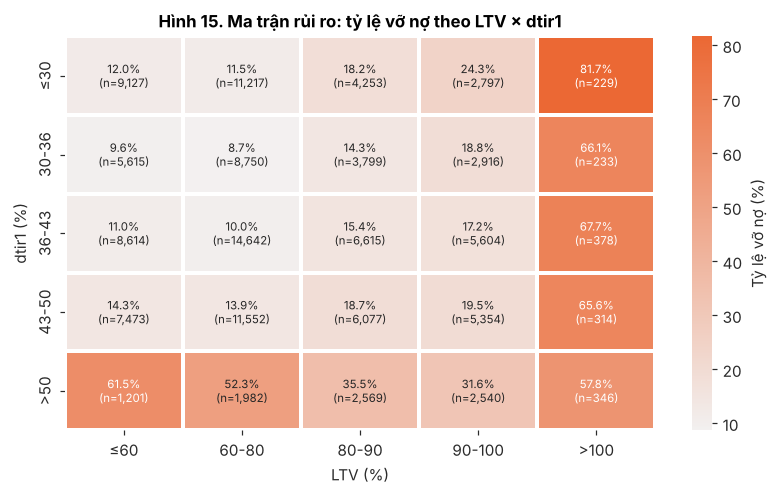

In [28]:
# Ma trận rủi ro kết hợp LTV × dtir1
ltv_band = pd.cut(clean["LTV"], [0, 60, 80, 90, 100, np.inf], labels=["≤60", "60-80", "80-90", "90-100", ">100"])
dti_band = pd.cut(clean["dtir1"], [0, 30, 36, 43, 50, np.inf], labels=["≤30", "30-36", "36-43", "43-50", ">50"])
piv = clean.assign(L=ltv_band, D=dti_band).pivot_table(index="D", columns="L", values="Status", aggfunc="mean", observed=False) * 100
cnt = clean.assign(L=ltv_band, D=dti_band).pivot_table(index="D", columns="L", values="Status", aggfunc="size", observed=False)
R["risk_matrix"] = {f"{d}|{l}": [round(float(piv.loc[d, l]), 1), int(cnt.loc[d, l])] for d in piv.index for l in piv.columns}
fig, ax = plt.subplots(figsize=(7.5, 4.6))
seq = sns.light_palette(C1, as_cmap=True)
annot = piv.round(1).astype(str) + "%\n(n=" + cnt.astype(int).map("{:,}".format) + ")"
sns.heatmap(piv, annot=annot, fmt="", cmap=seq, linewidths=1.5, linecolor="white", annot_kws={"size": 7.5}, cbar_kws={"label": "Tỷ lệ vỡ nợ (%)"}, ax=ax)
ax.grid(False); ax.set_xlabel("LTV (%)"); ax.set_ylabel("dtir1 (%)")
ax.set_title("Hình 15. Ma trận rủi ro: tỷ lệ vỡ nợ theo LTV × dtir1")
savefig("fig15_risk_matrix")

**Phân tích Hình 15.** Kết hợp hai biến cho thấy rủi ro cộng hưởng. Vùng an toàn nhất là dtir1 30–36% với LTV 60–80% (8,7%). Cột LTV > 100% (khoản vay lớn hơn giá trị tài sản) có tỷ lệ vỡ nợ 57,8–81,7% ở mọi mức dtir1 (tổng 1.500 hồ sơ). Hàng dtir1 > 50% cũng đều cao (31,6–61,5%). Điểm bất ngờ: dtir1 > 50% kết hợp LTV ≤ 60% có 61,5%, cao hơn dtir1 > 50% với LTV 90–100% (31,6%). Có thể đây là phân khúc vay đặc thù (ví dụ vay tái cấp vốn rút tiền mặt) cần điều tra thêm. Hàm ý chính sách: chỉ cần vượt một trong hai ngưỡng (LTV > 100% hoặc DTI > 50%) là đủ đẩy rủi ro lên gấp 2–5 lần mức trung bình 15,79%.

### 3.x Mô hình kiểm chứng: dự báo vỡ nợ trên hồ sơ đầy đủ (không dùng 3 cột rò rỉ)

In [29]:
y = clean["Status"].values
num_feats = ["loan_amount_w", "term", "property_value_w", "income_w", "Credit_Score", "LTV_w", "dtir1", "age_ord"]
cat_feats = ["loan_limit", "Gender", "approv_in_adv", "loan_type", "loan_purpose", "Credit_Worthiness", "open_credit",
             "Neg_ammortization", "interest_only", "lump_sum_payment", "occupancy_type",
             "total_units", "credit_type", "co-applicant_credit_type", "submission_of_application", "Region"]
X = clean[num_feats + cat_feats]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", RobustScaler())]), num_feats),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), cat_feats)])
models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42, class_weight="balanced"),
}
R["models"] = {}; rocs = {}; probs = {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("clf", m)]).fit(Xtr, ytr)
    p = pipe.predict_proba(Xte)[:, 1]
    rep = classification_report(yte, (p >= 0.5).astype(int), output_dict=True)
    R["models"][name] = {"auc": round(roc_auc_score(yte, p), 4), "recall_1": round(rep["1"]["recall"], 4),
                         "precision_1": round(rep["1"]["precision"], 4), "accuracy": round(rep["accuracy"], 4)}
    rocs[name] = roc_curve(yte, p); probs[name] = p; models[name] = pipe
# Đối chứng rò rỉ: chỉ dùng MỘT cờ "rate_of_interest bị thiếu" trên toàn bộ dữ liệu
R["auc_leak_flag_only"] = round(roc_auc_score(df["Status"], df["rate_of_interest"].isna().astype(int)), 4)
R["auc_artifact_flag_only"] = round(roc_auc_score(df["Status"], artifact.astype(int)), 4)
# Lift: gom tập test theo thập phân vị điểm rủi ro của Random Forest
p = probs["Random Forest"]
dec = pd.qcut(pd.Series(p).rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = pd.DataFrame({"y": yte, "d": dec.values}).groupby("d", observed=True)["y"].agg(["mean", "sum"])
lift["cum_capture_%"] = lift["sum"].cumsum() / lift["sum"].sum() * 100
R["lift"] = [{"decile": int(i), "rate": round(float(r["mean"] * 100), 2), "cum_capture": round(float(r["cum_capture_%"]), 2)} for i, r in lift.iterrows()]
print(json.dumps(R["models"], indent=1)); print("AUC chỉ với cờ thiếu rate_of_interest:", R["auc_leak_flag_only"], "| cờ hồ sơ không đầy đủ:", R["auc_artifact_flag_only"])
print(lift.round(3))

{
 "Logistic Regression": {
  "auc": 0.7292,
  "recall_1": 0.6408,
  "precision_1": 0.2892,
  "accuracy": 0.6946
 },
 "Random Forest": {
  "auc": 0.8128,
  "recall_1": 0.6039,
  "precision_1": 0.4471,
  "accuracy": 0.8196
 }
}
AUC chỉ với cờ thiếu rate_of_interest: 0.9973 | cờ hồ sơ không đầy đủ: 0.7133
     mean   sum  cum_capture_%
d                             
1   0.655  2180         41.516
2   0.274   911         58.865
3   0.168   557         69.472
4   0.132   438         77.814
5   0.103   343         84.346
6   0.078   260         89.297
7   0.063   208         93.258
8   0.043   144         96.001
9   0.034   112         98.134
10  0.029    98        100.000


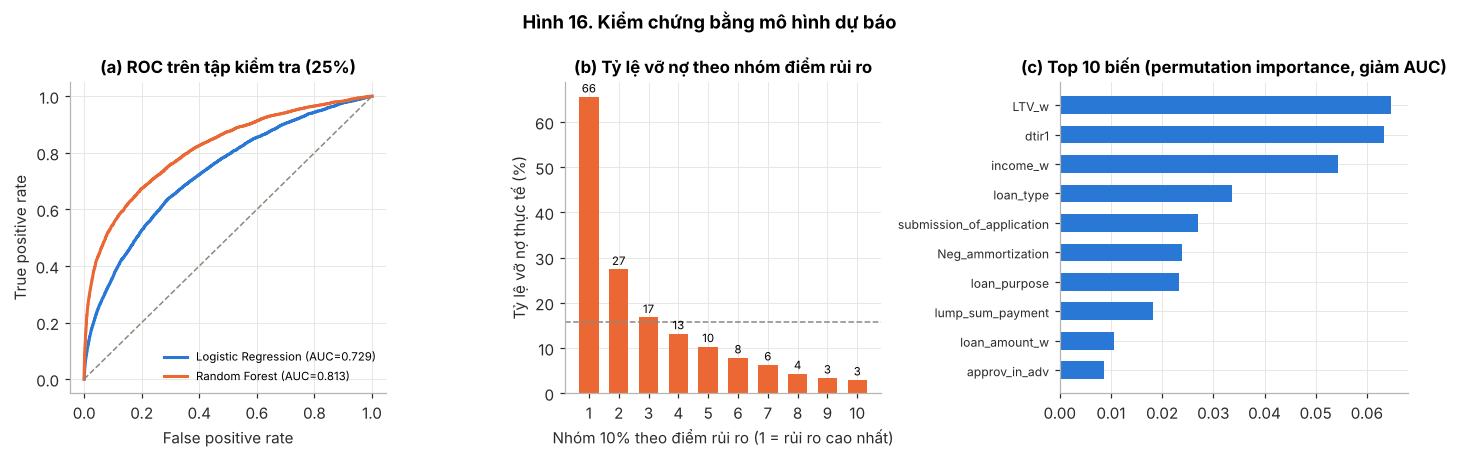

LTV_w                        0.0648
dtir1                        0.0633
income_w                     0.0543
loan_type                    0.0336
submission_of_application    0.0270
Neg_ammortization            0.0239
loan_purpose                 0.0233
lump_sum_payment             0.0182
loan_amount_w                0.0107
approv_in_adv                0.0086
occupancy_type               0.0060
property_value_w             0.0048
dtype: float64


In [30]:
from sklearn.inspection import permutation_importance
rf = models["Random Forest"]
pi = permutation_importance(rf, Xte, yte, scoring="roc_auc", n_repeats=3, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
R["perm_importance"] = imp.head(12).round(4).to_dict()
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for name, col in [("Logistic Regression", C0), ("Random Forest", C1)]:
    fpr, tpr, _ = rocs[name]
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC={R['models'][name]['auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(loc="lower right", fontsize=7.5)
axes[0].set_title("(a) ROC trên tập kiểm tra (25%)")
axes[1].bar(lift.index.astype(int), lift["mean"] * 100, color=C1, width=0.65)
axes[1].axhline(yte.mean() * 100, color=GRAY, ls="--", lw=1)
for i, v in zip(lift.index.astype(int), lift["mean"] * 100): axes[1].text(i, v + 1, f"{v:.0f}", ha="center", fontsize=7.5)
axes[1].set_xlabel("Nhóm 10% theo điểm rủi ro (1 = rủi ro cao nhất)"); axes[1].set_ylabel("Tỷ lệ vỡ nợ thực tế (%)")
axes[1].set_xticks(range(1, 11)); axes[1].set_title("(b) Tỷ lệ vỡ nợ theo nhóm điểm rủi ro")
top = imp.head(10)[::-1]
axes[2].barh(top.index, top.values, color=C0, height=0.6)
axes[2].set_title("(c) Top 10 biến (permutation importance, giảm AUC)"); axes[2].tick_params(axis="y", labelsize=8)
fig.suptitle("Hình 16. Kiểm chứng bằng mô hình dự báo", fontweight="bold")
savefig("fig16_model")
print(imp.head(12).round(4))

**Phân tích Hình 16.** Mô hình được huấn luyện trên hồ sơ đầy đủ, không dùng 3 cột rò rỉ, chia 75/25 có phân tầng. (a) Random Forest đạt AUC = 0,813, cao hơn Logistic Regression (0,729). Khoảng cách này xác nhận quan hệ phi tuyến/ngưỡng đã thấy ở Hình 9 và Hình 15. Ở ngưỡng 0,5, Random Forest bắt được 60,4% ca vỡ nợ (Recall) với Precision 44,7%. (b) Nhóm 10% hồ sơ rủi ro cao nhất có tỷ lệ vỡ nợ thực tế 65,54%, gấp 4,2 lần trung bình; 20% hồ sơ rủi ro nhất chứa 58,9% tổng số ca vỡ nợ, 30% chứa 69,5%. Năm nhóm 10% rủi ro thấp nhất chỉ có 2,9–7,8% vỡ nợ. (c) Theo permutation importance, ba biến quan trọng nhất là LTV (làm giảm AUC 0,065 khi bị xáo trộn), dtir1 (0,063) và income (0,054), tiếp theo là loan_type, submission_of_application, Neg_ammortization, loan_purpose và lump_sum_payment. Credit_Score không nằm trong top 12. Kết quả này trùng khớp với các kiểm định ở trên. Để so sánh: nếu để lọt cột rò rỉ, chỉ một cờ "rate_of_interest bị thiếu" đã cho AUC 0,997, một con số đẹp nhưng vô dụng khi chấm điểm hồ sơ mới.

### 3.y Tổng hợp kiểm định giả thuyết

| | Giả thuyết | Bằng chứng | Kết luận |
|---|---|---|---|
| H1 | Credit_Score càng thấp, vỡ nợ càng cao | Median 699 (không vỡ nợ) và 700 (vỡ nợ); Mann–Whitney p = 0,19; ρ = 0,004; tỷ lệ vỡ nợ theo nhóm điểm 15,1–16,5% | **Bác bỏ** |
| H2 | LTV càng cao, vỡ nợ càng cao | Median 74,5% và 79,4%; p < 10⁻²⁰⁰; r_rb = 0,14; nhóm LTV 95–103% có 26,8% so với 11,6% ở LTV 65–70%; LTV > 100% có 57,8–81,7% | **Chấp nhận (dạng chữ J)** |
| H3 | dtir1 càng cao, vỡ nợ càng cao | Median 38% và 42%; p ≈ 0; r_rb = 0,17; dtir1 ≤ 49% ổn định 12–16%, dtir1 49–61% có 43,1% | **Chấp nhận (dạng ngưỡng)** |
| H4 | Thu nhập càng cao, vỡ nợ càng thấp | Median 6.000 và 4.680; p ≈ 0; r_rb = −0,21; giảm từ 30,1% (thập phân vị thấp nhất) xuống khoảng 11% | **Chấp nhận** |
| H5 | Nhóm tuổi liên hệ với vỡ nợ (người trẻ rủi ro hơn) | χ² p ≈ 10⁻⁷⁴, V = 0,052; dạng chữ U: <25 có 19,7%, 25–34 có 13,3%, >74 có 19,5% | **Chấp nhận một phần (hiệu ứng yếu)** |
| H6 | Đặc điểm sản phẩm, vùng, giới tính liên hệ với vỡ nợ | lump_sum V = 0,177 (65,5% so với 15,0%); neg_amm V = 0,149; submission V = 0,127; loan_type V = 0,106; Region V = 0,051; Gender V = 0,080 | **Chấp nhận với sản phẩm; yếu với vùng/giới tính** |

## Giai đoạn 4. Đánh giá tác động và khuyến nghị

### 4.1 Phát hiện nổi bật
1. Chất lượng dữ liệu là phát hiện số một: 42,68% số ca vỡ nợ (15.648 hồ sơ) nằm trong nhóm hồ sơ ghi nhận không đầy đủ (thiếu giá trị tài sản, credit_type = EQUI, income = 0, thiếu tuổi), với tỷ lệ vỡ nợ 99,93%. Ba cột lãi suất, chênh lệch lãi suất và phí trả trước thiếu ở 99,45–100% hồ sơ vỡ nợ và gần 0% hồ sơ tốt. Đây là rò rỉ mục tiêu: một cờ thiếu duy nhất cho AUC 0,997.
2. Năng lực tài chính quyết định rủi ro: DTI > 49% làm tỷ lệ vỡ nợ tăng lên 43,1% (gấp 3,7 lần); LTV > 100% có 57,8–81,7%; nhóm thu nhập thấp nhất có 30,1% so với khoảng 11% ở nhóm thu nhập cao.
3. Cấu trúc sản phẩm quan trọng hơn nhân khẩu học: khoản vay trả gộp cuối kỳ vỡ nợ 65,5% (gấp 4,4 lần), khấu hao âm 32,7% (gấp 2,3 lần), vay kinh doanh (type2) 25,5%. Trong khi đó giới tính, vùng, tuổi chỉ có Cramér's V từ 0,05 đến 0,08.
4. Kênh nộp hồ sơ to_inst có tỷ lệ vỡ nợ 19,3%, gấp đôi kênh not_inst (9,6%). Hồ sơ vay chung (Joint) có rủi ro thấp nhất (11,4%).
5. Điểm tín dụng (Credit_Score) không có giá trị phân biệt (p = 0,19; ρ = 0,004) và phân phối đều tuyệt đối trên 500–900, khác hẳn điểm tín dụng thật. Giả thuyết H1 bị bác bỏ.
6. Một mô hình Random Forest không dùng biến rò rỉ đạt AUC 0,813; 20% hồ sơ rủi ro nhất chứa 58,9% số ca vỡ nợ, còn 50% hồ sơ rủi ro thấp nhất chỉ có 2,9–7,8% vỡ nợ.

### 4.2 Khuyến nghị

| Giải pháp | Nội dung | Căn cứ số liệu |
|---|---|---|
| **Sửa quy trình dữ liệu** | Kiểm toán lý do rate_of_interest, Upfront_charges, property_value bị bỏ trống ở hồ sơ vỡ nợ và lý do mọi hồ sơ EQUI đều vỡ nợ. Lưu ảnh chụp dữ liệu tại thời điểm xét duyệt (snapshot) thay vì dữ liệu cập nhật sau giải ngân. Ban hành từ điển dữ liệu chuẩn. | Loại bỏ rò rỉ; mô hình chấm điểm phản ánh đúng thông tin có lúc ra quyết định |
| **Trần LTV** | Đặt trần LTV khoảng 90–95%; với LTV > 100% bắt buộc bảo đảm bổ sung hoặc bảo hiểm khoản vay. | Nhóm LTV > 100% vỡ nợ 57,8–81,7%; nhóm 95–103% có 26,8% |
| **Trần DTI** | Đặt trần dtir1 khoảng 45–49%. Trên mức này yêu cầu người đồng vay, giảm số tiền vay hoặc kéo dài kỳ hạn. | Rủi ro tăng từ 16% lên 43% khi dtir1 vượt khoảng 49% |
| **Ngưỡng khoản vay/thu nhập** | Thẩm định khả năng trả nợ kỹ hơn khi khoản vay vượt 6 lần thu nhập năm hoặc thu nhập thuộc nhóm 10% thấp nhất. | Nhóm khoản vay/thu nhập cao nhất có 23,4%; thu nhập thấp nhất có 30,1% |
| **Kiểm soát sản phẩm rủi ro** | Hạn chế hoặc định giá rủi ro cao hơn cho khoản vay trả gộp cuối kỳ và khấu hao âm; phê duyệt cấp cao hơn cho vay kinh doanh (type2) và mục đích p2. | lpsm 65,5%, neg_amm 32,7%, type2 25,5%, p2 24,7% |
| **Rà soát kênh to_inst** | Rà soát chất lượng thẩm định của kênh nộp to_inst (đối tác, môi giới) và đặt chỉ tiêu chất lượng hồ sơ theo kênh. | Tỷ lệ vỡ nợ gấp đôi kênh not_inst (19,3% so với 9,6%) |
| **Phân luồng hồ sơ bằng mô hình** | Chấm điểm bằng mô hình: 20% rủi ro nhất chuyển thẩm định thủ công, 50% rủi ro thấp nhất xét duyệt nhanh. Ngưỡng cắt cần tính theo tổn thất kỳ vọng (PD × LGD × EAD). | Top 20% chứa 58,9% ca vỡ nợ; 50% thấp nhất chỉ 2,9–7,8% |
| **Đảm bảo công bằng** | Không dùng Gender, age làm biến ra quyết định; dùng chúng để kiểm tra mô hình có phân biệt đối xử hay không. | Hiệu ứng nhỏ (V ≤ 0,08) nhưng rủi ro pháp lý và uy tín lớn |

### 4.3 Giới hạn của dữ liệu
- Không có từ điển dữ liệu chính thức: ý nghĩa của các mã p1–p4, type1–3, l1/l2, cf/ncf, to_inst và đơn vị của income (giả định theo tháng) chỉ được suy luận từ tên cột.
- Dữ liệu chỉ có năm 2019 (một lát cắt): không kiểm định được tác động kinh tế vĩ mô, mùa vụ, và không kiểm tra được mô hình ngoài thời gian (out-of-time). Định nghĩa vỡ nợ (bao nhiêu ngày quá hạn, trong khoảng thời gian nào) không được công bố.
- Rò rỉ và thiếu không ngẫu nhiên (MNAR): việc tách nhóm hồ sơ không đầy đủ giúp phân tích trung thực hơn, nhưng làm mất 42,68% ca vỡ nợ. Kết luận ở Giai đoạn 3 chỉ đại diện cho hồ sơ được ghi nhận đầy đủ (có thể có thiên lệch chọn mẫu).
- Credit_Score có dấu hiệu bị ẩn danh hoặc sinh ngẫu nhiên (phân phối đều, tương quan 0 với mọi biến), nên không đánh giá được vai trò thật của điểm tín dụng.
- Dữ liệu quan sát cắt ngang chỉ cho thấy liên hệ, chưa chứng minh quan hệ nhân quả (ví dụ kênh to_inst có thể tập trung khách hàng rủi ro chứ bản thân kênh không gây ra vỡ nợ).

### 4.4 Hướng mở rộng
- Thu thập dữ liệu nhiều năm kèm ngày giải ngân và ngày vỡ nợ để kiểm định ngoài thời gian và áp dụng phân tích sống sót (thời gian đến khi vỡ nợ).
- Bổ sung lịch sử tín dụng thật, thông tin việc làm, biến vĩ mô (lãi suất, giá nhà, thất nghiệp theo vùng).
- Thử mô hình Gradient Boosting (XGBoost/LightGBM) kèm giải thích SHAP, hiệu chỉnh xác suất (calibration) và chọn ngưỡng theo chi phí.
- Xây dựng thẻ điểm (scorecard) WoE/IV để dễ giải trình với cơ quan quản lý; kiểm toán công bằng theo giới tính và độ tuổi.
- Làm việc với bộ phận vận hành để xác minh nguyên nhân của các trường bị bỏ trống, rồi chạy lại toàn bộ phân tích trên dữ liệu đã sửa.

In [31]:
with open(os.environ.get("RESULTS_JSON", "results.json"), "w", encoding="utf-8") as f:
    json.dump(R, f, ensure_ascii=False, indent=1, default=str)
print("Đã lưu kết quả.")

Đã lưu kết quả.
